### 1. Duck Typing (Informal Interfaces)

In [ ]:


class PDFReader:
    def extract_text(self) -> str:
        return "Text from PDF"

class EmailReader:
    def extract_text(self) -> str:
        return "Text from Email"

# This function accepts any object as long as it has an `extract_text` method
def print_content(reader):
    print(reader.extract_text())

print_content(PDFReader())   # Works
print_content(EmailReader()) # Works


Text from PDF
Text from Email


### 2. What is an abstract method and Abstract class?

- https://www.w3schools.com/python/ref_module_abc.asp

In [3]:
from abc import ABC, abstractmethod

class FileReader(ABC):
    @abstractmethod
    def extract_text(self) -> str:
        pass

class PDFReader(FileReader):
    def extract_text(self) -> str:
        return "Text from PDF"

# This will fail at runtime because it didn't implement `extract_text`:
class FaultyReader(FileReader):
    pass

reader = FaultyReader() # Raises TypeError: Can't instantiate abstract class...


TypeError: Can't instantiate abstract class FaultyReader without an implementation for abstract method 'extract_text'

### 3. What if i dont want to use `@abstractmethod`

In [1]:
from abc import ABC, abstractmethod

class FileReader(ABC):
    def extract_text(self) -> str:
        pass

class PDFReader(FileReader):
    def extract_text(self) -> str:
        return "Text from PDF"

# This will fail at runtime because it didn't implement `extract_text`:
class FaultyReader(FileReader):
    pass

reader = FaultyReader() # Raises TypeError: Can't instantiate abstract class...


- it will not be an abstract method.


### 4.1 What is cls and classmethod in python?


In [8]:
class Pizza:
    # A class variable shared by all pizzas
    base_price = 10  

    def __init__(self, toppings):
        self.toppings = toppings

    # A class method using 'cls'
    @classmethod
    def update_base_price(cls, new_price):
        # cls points to the Pizza class, allowing us to change class attributes
        cls.base_price = new_price  

# Call the method directly on the class (no instance needed)
Pizza.update_base_price(12)
print(Pizza.base_price)  # Output: 12


12


`ctrl+shift+k` to delete a line in vscode

In [10]:
class Pizza:
    base_price = 10  

    def __init__(self, toppings):
        self.toppings = toppings

    def update_base_price(cls, new_price):
        cls.base_price = new_price  

Pizza.update_base_price(12)
print(Pizza.base_price)  # Output: 12


TypeError: Pizza.update_base_price() missing 1 required positional argument: 'new_price'

In [ ]:
class Pizza:
    base_price = 10

    def update_base_price(cls, new_price):
        cls.base_price = new_price

piz1=Pizza()
print(piz1.base_price)
piz2=Pizza()
print(piz2.base_price)

Pizza.update_base_price(Pizza, 12)
print(Pizza.base_price)  # 12
print(piz1.base_price)

piz2=Pizza()
print(piz2.base_price)

10
10
12
12
12


In [ ]:
class Pizza:
    base_price = 10  

    def __init__(self, toppings):
        self.toppings = toppings

    def update_base_price(new_price):
        base_price = new_price  

Pizza.update_base_price(12)
print(Pizza.base_price) 

# here we can call the function but it cant update the base price of the class


10


- https://chatgpt.com/share/6adc9382-c078-83e8-98ea-c44bf6838107

### 4. What is a staticmethod in python?

- A static method in Python is a method defined inside a class that does not depend on instance (self) or class (cls) data. It behaves exactly like a regular function, but it is placed inside a class namespace because it logically belongs there.

In [2]:
class MathOperations:
    
    @staticmethod
    def add(a, b):
        # Has no access to the class or instance state
        return a + b

# You call it directly on the Class without creating an object
result = MathOperations.add(5, 10)
print(result)  # Output: 15


15


In [ ]:
class MathOperations:
    
    
    def add(cls,a, b):
        return a + b

result = MathOperations.add(5, 10)
print(result)  # Output: 15


TypeError: MathOperations.add() missing 1 required positional argument: 'b'

### 5. where to use static method and class methods

- https://chatgpt.com/share/6adc94bd-4f30-83ee-b579-0cc9a77781a0

### 6. What are dataclasses in python?

The Python dataclasses module provides the @dataclass decorator to automatically generate boilerplate dunder methods like __init__, __repr__, and __eq__ based on PEP 526 type annotations. It simplifies creating classes whose primary purpose is to store data.

🛠️ Basic Usage

To create a data class, import the decorator from the dataclasses module and apply it to your class. Type hints are mandatory for field inclusion.

In [15]:
from dataclasses import dataclass

@dataclass
class Product:
    name: str
    price: float
    quantity: int = 0  # Default value

# Automatically generates __init__
item = Product(name="Laptop", price=999.99, quantity=2)

# Automatically generates a clean __repr__
print(item)  
# Output: Product(name='Laptop', price=999.99, quantity=2)

# Automatically generates __eq__ (compares values, not memory addresses)
item2 = Product(name="Laptop", price=999.99, quantity=2)
print(item == item2)  # Output: True


Product(name='Laptop', price=999.99, quantity=2)
True



⚙️ Core Customization & Key Features

- Mutable Default Values: You cannot use mutable defaults like [] or {} directly. Instead, use the field() function with a default_factory to ensure each instance gets its own independent copy.
- Immutability (frozen=True): Setting frozen=True makes instances read-only. Attempting to modify fields after initialization will raise a FrozenInstanceError.
- Post-Initialization (`__post_init__`): Used to compute derived fields or validate data right after the generated `__init__` finishes running.
- Memory Optimization (slots=True): Available in Python 3.10+, this builds the class using `__slots__`, reducing memory footprint and speeding up attribute access.

In [16]:
from dataclasses import dataclass, field

@dataclass(frozen=True, slots=True)
class User:
    username: str
    email: str
    # Handles mutable default cleanly
    roles: list[str] = field(default_factory=list) 
    # Excludes sensitive data from the string representation
    password_hash: str = field(repr=False, default="***") 

    def __post_init__(self):
        # Perform validation (Note: for frozen classes, adjustments require a workaround)
        if "@" not in self.email:
            raise ValueError("Invalid email address")



🧰 Built-in Serialization Utilities

The module provides helpers to easily convert your structured data class instances into primitive data structures:
- asdict(instance): Recursively converts a dataclass instance into a standard Python dictionary (perfect for JSON serialization).
- astuple(instance): Converts the instance into a tuple of its field values.

### 7. Access Modifiers (Public, private protected)

- In Python, access modifiers are implemented via naming conventions rather than strict enforcement or keywords. Unlike languages like Java or C++, Python does not prevent you from accessing internal variables directly; it relies on the philosophy that "we are all consenting adults here".
- Python features three conceptual levels of access control: Public, Protected, and Private.

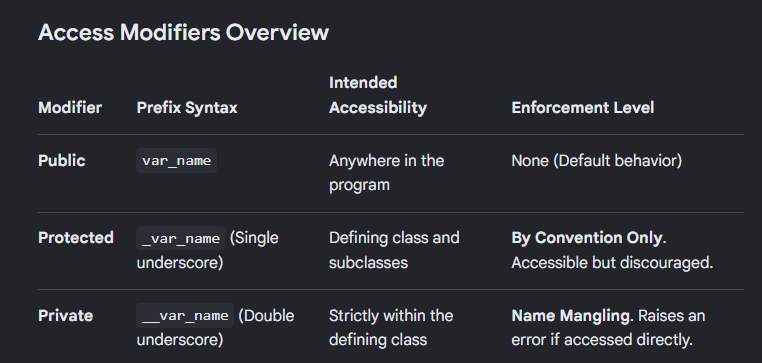

In [ ]:
class Account:
    def __init__(self, owner, balance, pin):
        self.owner = owner          # Public: Accessible everywhere
        self._balance = balance      # Protected: Internal / Subclass use only
        self.__pin = pin            # Private: Strictly hidden inside the class

    def get_pin(self):
        return self.__pin           # Allowed: Inside the class boundary

# --- Interacting with the Object ---
acc = Account("Alice", 5000, 1234)

# 1. Public Access
print(acc.owner)       # Output: Alice

# 2. Protected Access 
print(acc._balance)    # Output: 5000 (Works, but IDEs/Linters will warn you)

# 3. Private Access
# print(acc.__pin)     # Raises AttributeError!
# print(acc.__pin)
print(acc.get_pin())





Alice
5000
1234



- How Private Members Actually Work: Name Mangling

- When you use a double underscore (e.g., __pin), Python internally changes the name of that attribute to _ClassName__attributeName. This mechanism is called Name Mangling. Its primary goal is to prevent name clashes in inheritance hierarchies, rather than acting as a bulletproof security barrier.
- You can technically bypass this restriction by using its mangled name:

In [5]:
acc._Account__pin=2345
print(acc._Account__pin)  # Output: 1234


2345


- https://www.w3schools.com/python/python_encapsulation.asp

- https://www.w3schools.com/python/python_inheritance.asp

### 8. override and overload in python

- In Python, method overriding is natively supported and allows a child class to change the behavior of a parent class method.
-  Method overloading (having multiple methods with the same name but different arguments) is not natively supported; defining a duplicate method name will simply overwrite the previous one.

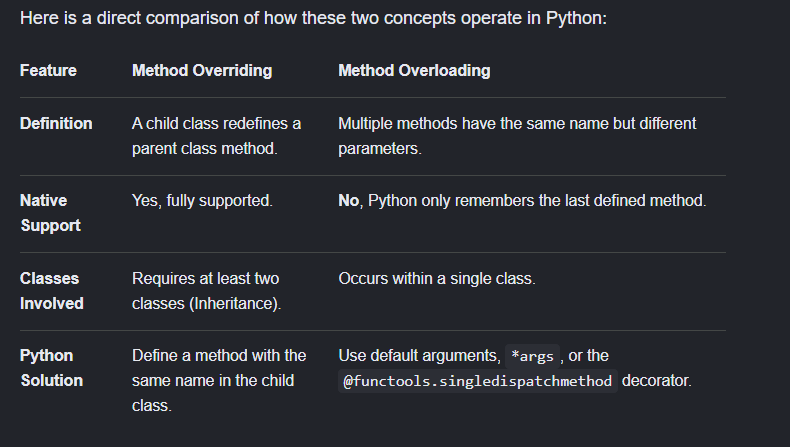


1. Method Overriding (Natively Supported)

Overriding happens when a subclass provides a specific implementation of a method that is already provided by its base/parent class

In [7]:
class Animal:
    def make_sound(self):
        return "Generic animal sound"

class Dog(Animal):
    # Overriding the parent method
    def make_sound(self):
        return "Bark!"

# Usage
animal = Animal()
dog = Dog()

print(animal.make_sound())  # Output: Generic animal sound
print(dog.make_sound())     # Output: Bark!


Generic animal sound
Bark!



2. Method Overloading (Simulated / Workarounds)

If you write two methods with the same name in Python, the second one overwrites the first. To achieve overloading behavior, you have two primary options:

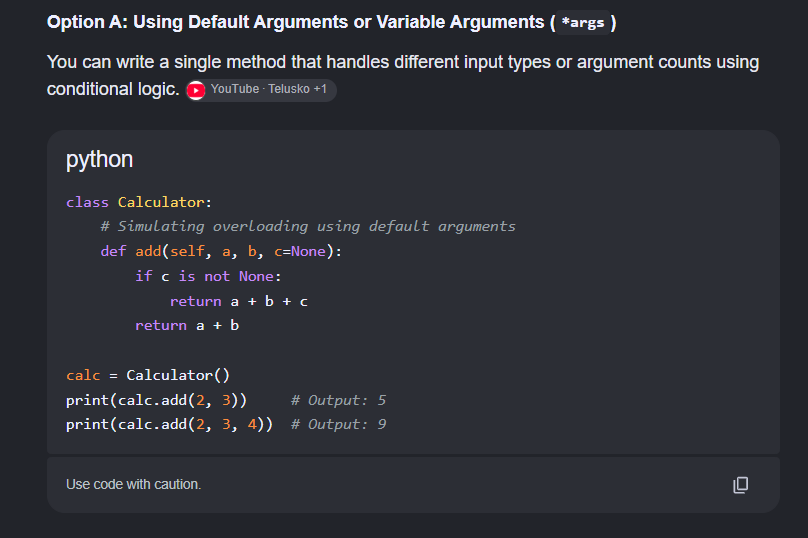


Option B: Using @singledispatchmethod (The Clean Way)

If you want clean, language-level overloading based on the type of the first argument, you can use the standard library's functools module:

In [9]:
from functools import singledispatchmethod

class Formatter:
    @singledispatchmethod
    def process(self, data):
        raise TypeError("Unsupported type")

    # Overload for integers
    @process.register
    def _(self, data: int):
        return f"Processing integer: {data}"

    # Overload for strings
    @process.register
    def _(self, data: str):
        return f"Processing string: {data.upper()}"

fmt = Formatter()
print(fmt.process(10))     # Output: Processing integer: 10
print(fmt.process("abc"))  # Output: Processing string: ABC


Processing integer: 10
Processing string: ABC


In [11]:
# Method Overriding
class Bla:
    def hu(self):
        print("hu 1")
    
    def hu(self):
        print("hu 2")

bla=Bla()
bla.hu()


hu 2


In [12]:
from typing import Final

# Java: final int MAX_VALUE = 100;
MAX_VALUE: Final = 100

# This will trigger an error in static type checkers (like MyPy or IDEs)
MAX_VALUE = 200 


In [13]:
from typing import final

class Parent:
    @final
    def secure_method(self):
        print("This method cannot be overridden.")

class Child(Parent):
    # Type checkers will flag this as a compilation-style error
    def secure_method(self): 
        print("Trying to override.")


In [14]:
from typing import final

@final
class ImmutableData:
    pass

# Type checkers will flag this inheritance as an error
class MaliciousExtension(ImmutableData): 
    pass


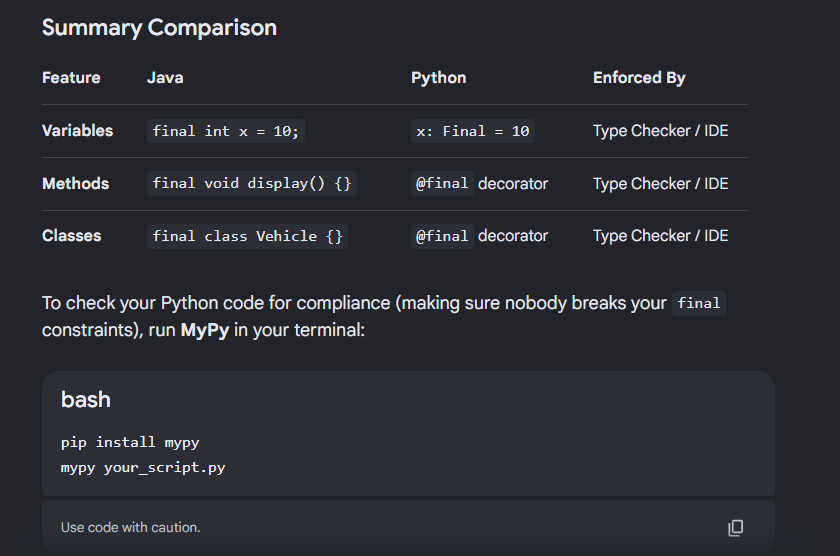

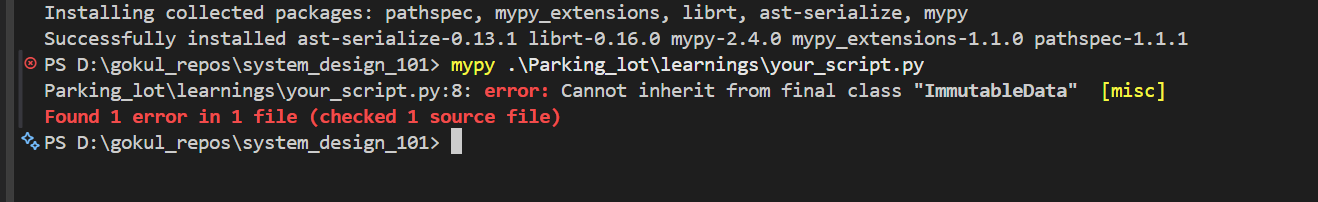

### 9. static in python

In Python, the word "static" refers to variables or methods that belong to the class itself rather than to individual instances (objects) of that class. Unlike languages like Java or C++, Python does not have a literal static keyword, but achieves the exact same behavior through positioning and decorators.

A static variable is shared by all instances of a class. It is defined directly inside the class body but outside any methods

In [15]:
class Employee:
    # Static variable (shared across all instances)
    company_name = "Tech Corp" 

    def __init__(self, name):
        # Instance variable (unique to each instance)
        self.name = name 

# Access via the class itself
print(Employee.company_name)  # Output: Tech Corp

# Access via instances
emp1 = Employee("Alice")
emp2 = Employee("Bob")
print(emp1.company_name)      # Output: Tech Corp

# Updating the static variable updates it for everyone
Employee.company_name = "Mega Corp"
print(emp2.company_name)      # Output: Mega Corp


Tech Corp
Tech Corp
Mega Corp


Warning: Avoid updating a static variable using an instance (e.g., emp1.company_name = "New"). Doing so creates a new instance variable for that specific object only, shadowing the class variable instead of modifying it

In [16]:
emp2.company_name="new"
print(emp2.company_name)
print(Employee.company_name)
print(emp1.company_name)

new
Mega Corp
Mega Corp



2. Static Methods (@staticmethod)

A static method is a function inside a class that does not receive an implicit first argument (neither self nor cls). It cannot access or modify instance or class attributes directly. It acts like a regular utility function grouped inside the class for logical organization.

In [17]:
class MathUtils:
    @staticmethod
    def add(x, y):
        return x + y

# Call directly using the class name without creating an object
result = MathUtils.add(5, 10)
print(result)  # Output: 15


15


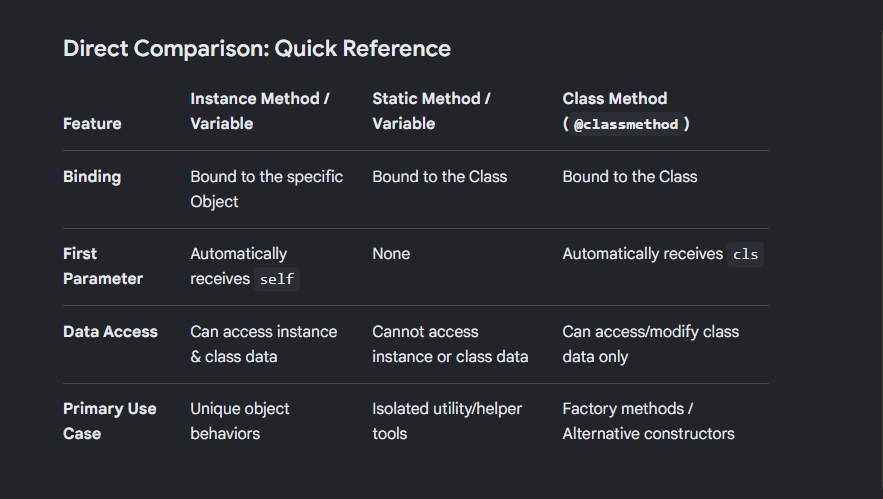

### threading in python

In [18]:
import threading
import time

def compute_square(number):
    print(f"Calculating square for {number}...")
    time.sleep(1) # Simulates an I/O delay
    print(f"Square: {number * number}")

# 1. Create the thread object
# Note: args must be passed as a tuple, hence the trailing comma
thread1 = threading.Thread(target=compute_square, args=(5,))

# 2. Start execution
thread1.start()

# 3. Wait for the thread to finish before moving the main script forward
thread1.join()

print("Main thread execution complete.")


Calculating square for 5...
Square: 25
Main thread execution complete.


- https://medium.com/@sharif-42/threading-in-python-27f3519bd4e1

### Builder design pattern

- The Builder Pattern is a creational design pattern used to construct complex objects step by step. In many programming languages (like Java or C++), it is heavily used to avoid "telescoping constructors"—a situation where a class has too many optional parameters in its constructor.
- In Python, because the language supports keyword arguments (**kwargs) and default parameters, a traditional builder pattern isn't always strictly necessary. However, Python developers frequently use a modified, idiomatic version of this pattern to handle complex configurations, data validation, and object immutability.


The Two Approaches to Builders in Python


1. The Idiomatic (Pythonic) Fluent Builder

This is the most common approach. It leverages method chaining (returning self from each method) to create a highly readable, English-like syntax for building an object.

In [ ]:
class Burger:
    def __init__(self):
        self.bun = "Regular"
        self.patties = 1
        self.cheese = False
        self.sauces = []

    def __str__(self):
        return f"Burger with {self.bun} bun, {self.patties} patty/patties, Cheese: {self.cheese}, Sauces: {self.sauces}"

class BurgerBuilder:
    def __init__(self):
        self.burger = Burger()

    def set_bun(self, bun_type: str):
        self.burger.bun = bun_type
        return self  # <-- Crucial for method chaining

    def add_patties(self, count: int):
        self.burger.patties = count
        return self

    def add_cheese(self):
        self.burger.cheese = True
        return self

    def add_sauce(self, sauce: str):
        self.burger.sauces.append(sauce)
        return self

    def build(self) -> Burger:
        # You can add final validation logic here before returning the object
        if self.burger.patties < 1:
            raise ValueError("A burger must have at least one patty!")
        return self.burger

# --- Usage ---
custom_burger = (
    BurgerBuilder()
    .set_bun("Brioche")
    .add_patties(2)
    .add_cheese()
    .add_sauce("BBQ")
    .add_sauce("Mayo")
    .build()
)

print(custom_burger)
# Output: Burger with Brioche bun, 2 patty/patties, Cheese: True, Sauces: ['BBQ', 'Mayo']



2. The Canonical (Gang of Four) Builder

If you are designing a highly complex system (like a document converter or a game engine) where you need to create different variations of a product using the exact same construction steps, you use a Director.

In [19]:
from abc import ABC, abstractmethod

# 1. The Complex Product
class Computer:
    def __init__(self):
        self.parts = {}

# 2. The Abstract Builder Interface
class ComputerBuilder(ABC):
    @abstractmethod
    def configure_cpu(self): pass
    
    @abstractmethod
    def configure_ram(self): pass

# 3. Concrete Builder A
class GamingComputerBuilder(ComputerBuilder):
    def __init__(self): self.computer = Computer()
    def configure_cpu(self): self.computer.parts['cpu'] = "Intel i9"
    def configure_ram(self): self.computer.parts['ram'] = "32GB"
    def get_result(self): return self.computer

# 4. Concrete Builder B
class OfficeComputerBuilder(ComputerBuilder):
    def __init__(self): self.computer = Computer()
    def configure_cpu(self): self.computer.parts['cpu'] = "Intel i3"
    def configure_ram(self): self.computer.parts['ram'] = "8GB"
    def get_result(self): return self.computer

# 5. The Director orchestrates the build steps
class DesktopDirector:
    def __init__(self, builder: ComputerBuilder):
        self.builder = builder

    def build_minimal_pc(self):
        self.builder.configure_cpu()
        
    def build_high_end_pc(self):
        self.builder.configure_cpu()
        self.builder.configure_ram()



When should you use a Builder in Python?

As a rule of thumb, skip the builder pattern for simple data models and use standard __init__ constructor methods or Python dataclasses instead. Implement a builder class only when:
-  The constructor parameter count explodes: Your initialization requires 5+ arguments, many of which are optional strings or configurations.
-  Step sequence matters: The object cannot be constructed instantly; certain fields must be computed or validated in a strict multi-step workflow.
-  Immutability with mutable staging: You want to generate an immutable object (like a frozen dataclass or namedtuple), but the logic to parse and collect its initial components requires a mutable staging class.
-  Real-world abstractions: Building dynamic structures like complex SQL Query Engines (.select().where().limit()) or HTTP Request clients